# phase 8 — วิดีโอจริง: ก่อนจูน vs หลังจูน

**สรุป:** คลิปที่อัดเอง WER 0.700 → 0.600 (คำเกินลดลง) · ระบบยืนยันคำเพิ่มขึ้นโดยไม่มีคำไหนผิด · data_test เท่าเดิม

* ก่อนจูน = `accept_min` 0.8 · `p_sign_min` 0.65 · ไม่มีกฎเห็นมือ · หลังจูน = 0.7 · 0.55 · `min_hand_frac` 0.3
* ชุด: data_test 5 คลิป · คลิปที่อัดเอง 5 คลิป · คลิปที่อัดเอง ตัดหัวท้าย + 2 คลิปใหม่ (7 คลิป) · คลังคำ = บทสนทนา
* รันด้วย `pitty/scripts/my_eval.py` (ก่อนจูน: ตั้ง `SPOT_OVERRIDE` + `ACCEPT_MIN`) · ตารางผลรวม: `pitty/scripts/team_metrics.py`

## ผลรวม

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display, Markdown
E = Path(r"C:/Users/ppich/OneDrive/Desktop/tu/yrs4/DSI490/Main_demo/cache/pitty_eval"); sys.path.insert(0, r"C:/Users/ppich/OneDrive/Desktop/tu/yrs4/DSI490/Main_demo/pitty/scripts")
from team_metrics import show
show(real_only=True)

ตัววัด,ชุดทดสอบ,ก่อนจูน,หลังจูน,ผล
WER (ต่ำ = ดี),data_test (5 คลิป),0.752,0.752,เท่าเดิม
,คลิปที่อัดเอง (5 คลิป),0.700,0.600,ดีขึ้น
,คลิปที่อัดเอง ตัดหัวท้าย (7 คลิป),0.581,0.581,เท่าเดิม
Recall@1 (สูง = ดี),data_test (5 คลิป),0.32,0.32,เท่าเดิม
,คลิปที่อัดเอง (5 คลิป),0.58,0.58,เท่าเดิม
,คลิปที่อัดเอง ตัดหัวท้าย (7 คลิป),0.52,0.52,เท่าเดิม
คำที่ระบบยืนยัน (ถูก/ทั้งหมด),data_test (5 คลิป),2/2,2/2,เท่าเดิม
,คลิปที่อัดเอง (5 คลิป),2/2,2/2,เท่าเดิม
,คลิปที่อัดเอง ตัดหัวท้าย (7 คลิป),3/3,6/6,เพิ่มขึ้น
Count error (ต่ำ = ดี),data_test (5 คลิป),0.60,0.60,เท่าเดิม


## รายวิดีโอ — คำที่ระบบยืนยัน ก่อน vs หลัง
**ยืนยัน** = คำที่ผ่านเกณฑ์ → ใส่ในประโยค/พูดออกเสียง · ✓ ถูก ✗ ผิด · **ระบบอ่านได้** = คำอันดับ 1 ของทุกท่า

In [2]:
def per_video(s):
    B = {r['video']: r for r in json.loads((E / f'{s}_base' / 'metrics.json').read_text(encoding='utf-8'))['videos']}
    A = {r['video']: r for r in json.loads((E / s / 'metrics.json').read_text(encoding='utf-8'))['videos']}
    mark = lambda acc, ref: ' '.join(f"{w}{'✓' if w in ref.split() else '✗'}" for w in str(acc).split()) or '–'
    return pd.DataFrame([{'วิดีโอ': v, 'เฉลย': A[v]['ref'],
                          'ยืนยัน (ก่อน)': mark(B[v]['accepted'], B[v]['ref']), 'ยืนยัน (หลัง)': mark(A[v]['accepted'], A[v]['ref']),
                          'ระบบอ่านได้ (ก่อน)': B[v]['top1'], 'ระบบอ่านได้ (หลัง)': A[v]['top1'],
                          'WER ก่อน → หลัง': f"{B[v]['WER']:.2f} → {A[v]['WER']:.2f}"} for v in A if v in B])
for s, name in [('data_test', 'data_test'), ('mine', 'คลิปที่อัดเอง'), ('mine2', 'คลิปที่อัดเอง ตัดหัวท้าย + 2 คลิปใหม่')]:
    display(Markdown(f'### {name}')); display(per_video(s).style.hide(axis='index').set_properties(**{'text-align': 'left'}))

### data_test

วิดีโอ,เฉลย,ยืนยัน (ก่อน),ยืนยัน (หลัง),ระบบอ่านได้ (ก่อน),ระบบอ่านได้ (หลัง),WER ก่อน → หลัง
test1,สวัสดี สบายดี ชอบ โกรธ แมว แฟน ปรบมือ,แมว✓,แมว✓,สวัสดี สบายดี ชอบ หก แมว ข้าว แมว,สวัสดี สบายดี ชอบ หก แมว ข้าว แมว,0.43 → 0.43
ฉันปลอบเพื่อนร้องไห้,ฉัน ปลอบใจ เพื่อน ร้องไห้,เพื่อน✓,เพื่อน✓,เพื่อน ดู ข้าว สงสาร,เพื่อน ดู ข้าว สงสาร,1.00 → 1.00
ฉันรักเพื่อน,ฉัน รัก เพื่อน,–,–,ฉัน รัก,ฉัน รัก,0.33 → 0.33
พ่อดื่มน้ำ,พ่อ ดื่ม น้ำ,–,–,ศูนย์ พ่อ น้า ศูนย์,ศูนย์ พ่อ น้า ศูนย์,1.00 → 1.00
ไปทานข้าวด้วยกันมั้ย,ไป กิน ข้าว ด้วยกัน ไหม,–,–,คุณ ฉัน กิน ไป,คุณ ฉัน กิน ไป,1.00 → 1.00


### คลิปที่อัดเอง

วิดีโอ,เฉลย,ยืนยัน (ก่อน),ยืนยัน (หลัง),ระบบอ่านได้ (ก่อน),ระบบอ่านได้ (หลัง),WER ก่อน → หลัง
พรุ่งนี้ฉันไปโรงเรียน,พรุ่งนี้ ฉัน ไป โรงเรียน,–,–,สวัสดี ฉัน ยาย โรงเรียน,สวัสดี ฉัน ยาย โรงเรียน,0.50 → 0.50
สวัสดีฉันชื่อ P,สวัสดี ฉัน ชื่อ P,ฉัน✓ ชื่อ✓,ฉัน✓ ชื่อ✓,สวัสดี ฉัน ชื่อ P ข้าว กิน,สวัสดี ฉัน ชื่อ P,0.50 → 0.00
ฉันคิดถึงแม่,ฉัน คิดถึง แม่,–,–,เกิด ฉัน เที่ยว แม่ กิน,เกิด ฉัน เที่ยว แม่ กิน,1.00 → 1.00
ฉันชอบกินขนมปัง,ฉัน ชอบ กิน ขนมปัง,–,–,ฉัน กิน ขนมปัง เกิด,ฉัน กิน ขนมปัง เกิด,0.50 → 0.50
พรุ่งนี้ไปเที่ยว,พรุ่งนี้ ฉัน ไป เที่ยว,–,–,แฟน น้อง ที่ไหน,แฟน น้อง ที่ไหน,1.00 → 1.00


### คลิปที่อัดเอง ตัดหัวท้าย + 2 คลิปใหม่

วิดีโอ,เฉลย,ยืนยัน (ก่อน),ยืนยัน (หลัง),ระบบอ่านได้ (ก่อน),ระบบอ่านได้ (หลัง),WER ก่อน → หลัง
พรุ่งนี้ฉันไปโรงเรียน,พรุ่งนี้ ฉัน ไป โรงเรียน,–,–,แฟน สวัสดี ฉัน ยาย โรงเรียน ข้าว,แฟน สวัสดี ฉัน ยาย โรงเรียน ข้าว,1.00 → 1.00
สวัสดีฉันชื่อ P,สวัสดี ฉัน ชื่อ P,สวัสดี✓,สวัสดี✓ ฉัน✓ ชื่อ✓,สวัสดี ฉัน ชื่อ P,สวัสดี ฉัน ชื่อ P,0.00 → 0.00
ฉันคิดถึงแม่,ฉัน คิดถึง แม่,–,ฉัน✓,ฉัน แม่,ฉัน แม่,0.33 → 0.33
ฉันชอบกินขนมปัง,ฉัน ชอบ กิน ขนมปัง,–,–,ฉัน กิน ขนมปัง,ฉัน กิน ขนมปัง,0.25 → 0.25
พรุ่งนี้ฉันไปเที่ยว,พรุ่งนี้ ฉัน ไป เที่ยว,–,–,น้อง เที่ยว,น้อง เที่ยว,0.75 → 0.75
ฉันรักเพื่อน,ฉัน รัก เพื่อน,ฉัน✓ เพื่อน✓,ฉัน✓ เพื่อน✓,ฉัน เกิด เพื่อน,ฉัน เกิด เพื่อน,0.33 → 0.33
วันหยุดพ่อชอบไปตลาด,วันหยุด พ่อ ชอบ ไป ตลาด,–,–,เที่ยว ไป กิน ฉัน เพื่อน แม่ ขนมปัง,เที่ยว ไป กิน ฉัน เพื่อน แม่ ขนมปัง,1.40 → 1.40


## ค่าความมั่นใจต่อท่า (หลังจูน)
แต่ละช่อง = ท่าที่ระบบตรวจเจอ 1 ท่า: ภาพกลางท่า · เวลา · **p = ความมั่นใจ** (เขียว ยืนยัน ≥ 0.7 · ส้ม ไม่แน่ใจ · แดง ไม่รู้จัก) · 3 คำที่ใกล้ที่สุด

### data_test

**test1**

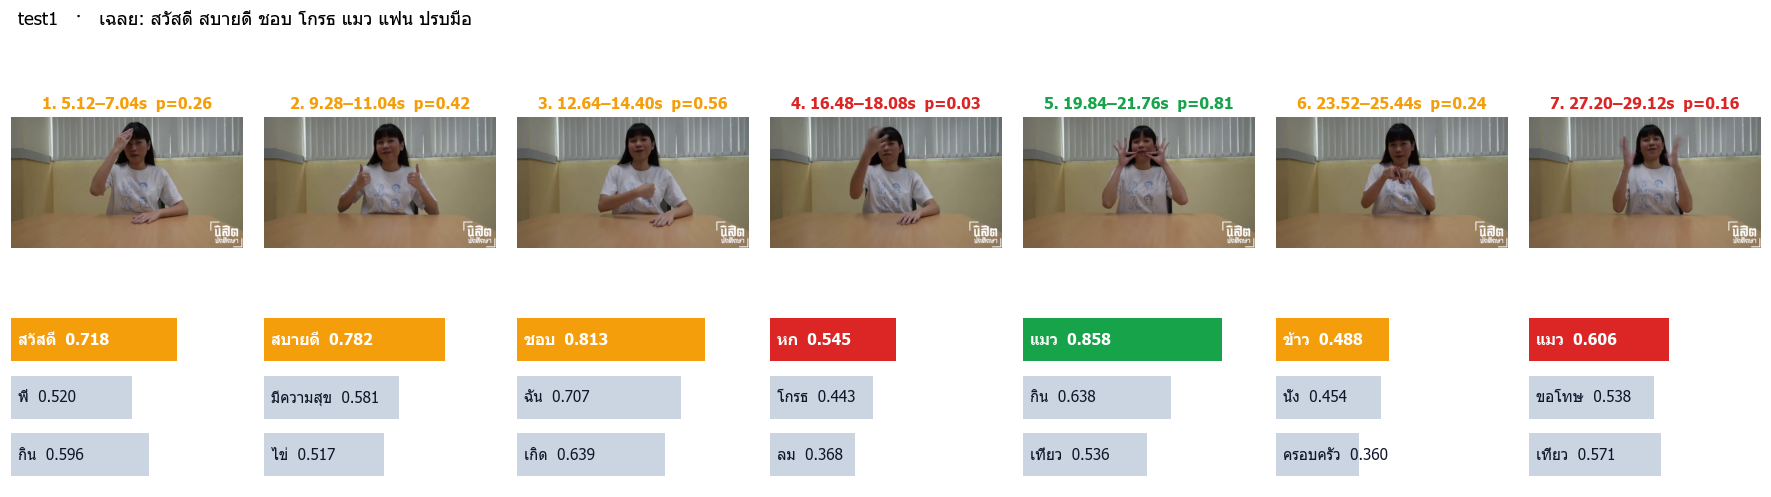

**ฉันปลอบเพื่อนร้องไห้**

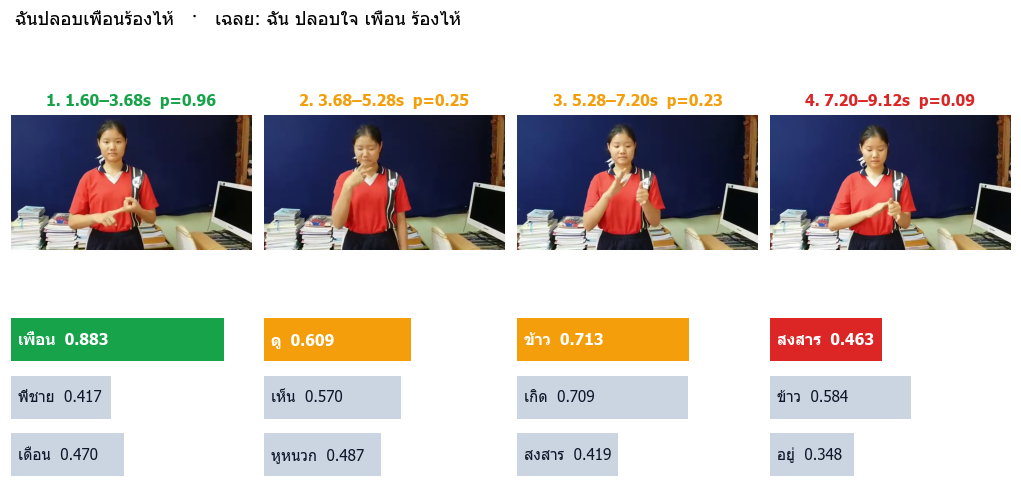

**ฉันรักเพื่อน**

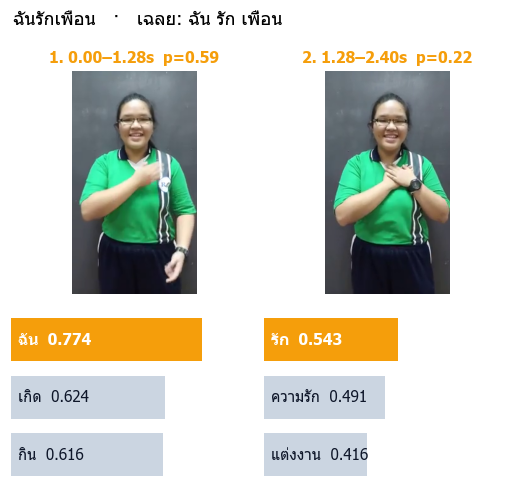

**พ่อดื่มน้ำ**

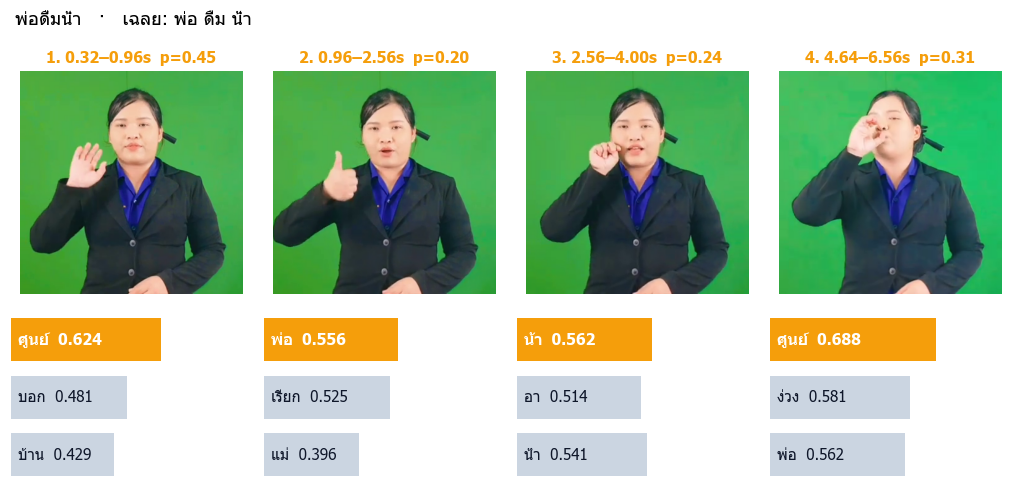

**ไปทานข้าวด้วยกันมั้ย**

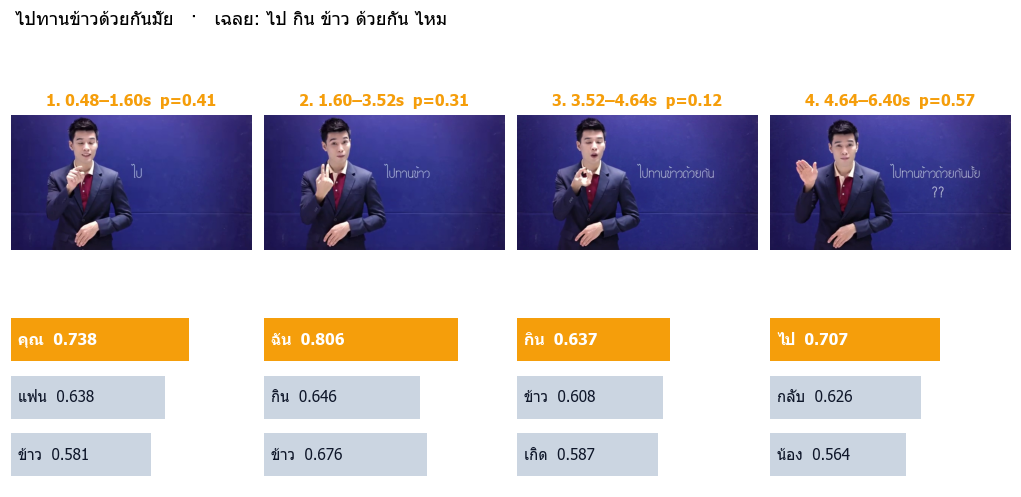

### คลิปที่อัดเอง ตัดหัวท้าย + 2 คลิปใหม่

**ฉันคิดถึงแม่**

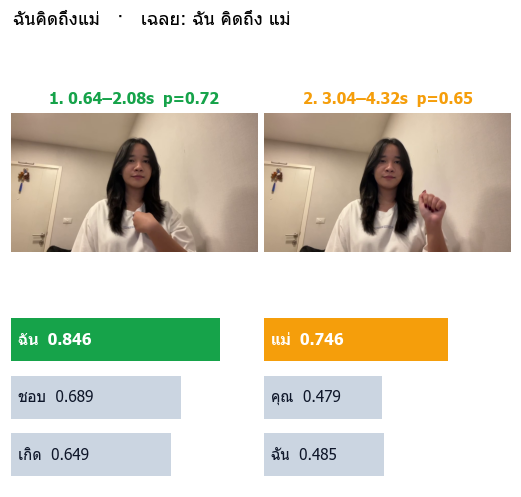

**ฉันชอบกินขนมปัง**

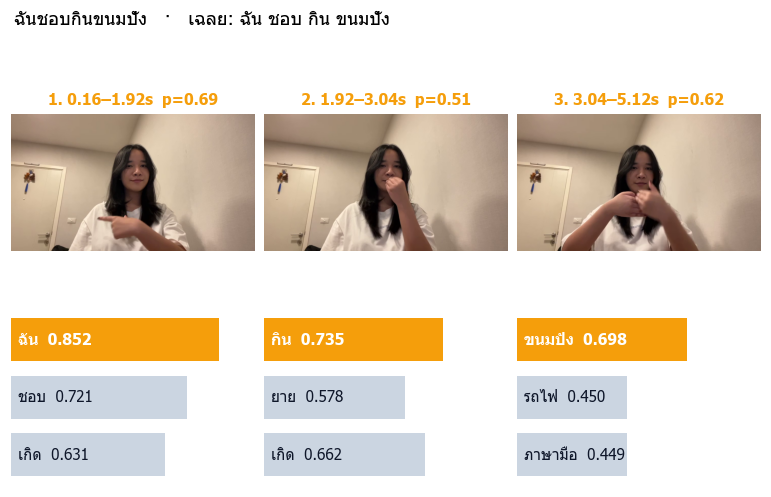

**ฉันรักเพื่อน**

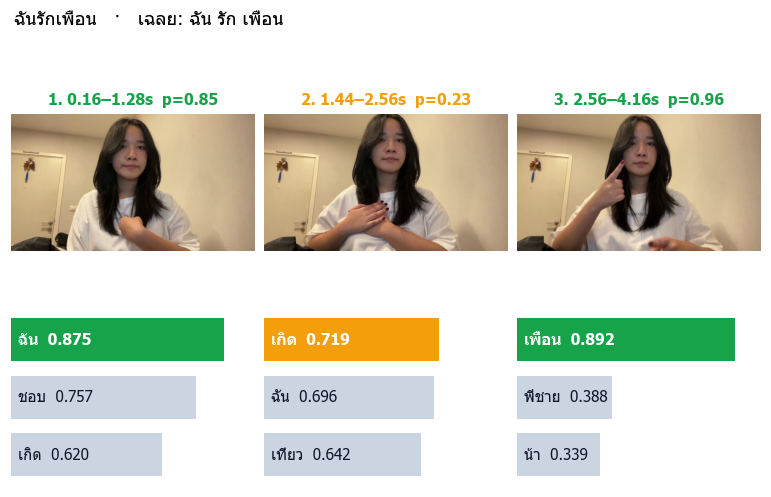

**พรุ่งนี้ฉันไปเที่ยว**

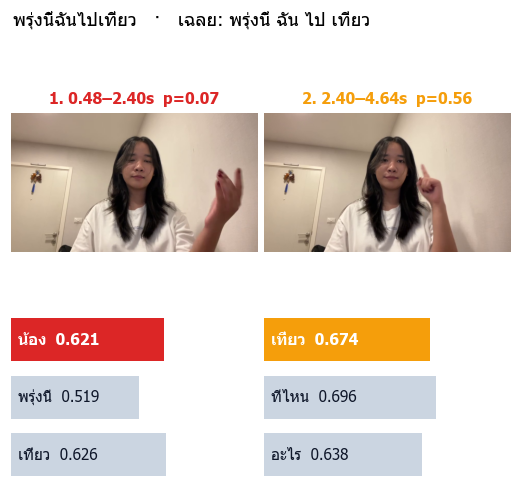

**พรุ่งนี้ฉันไปโรงเรียน**

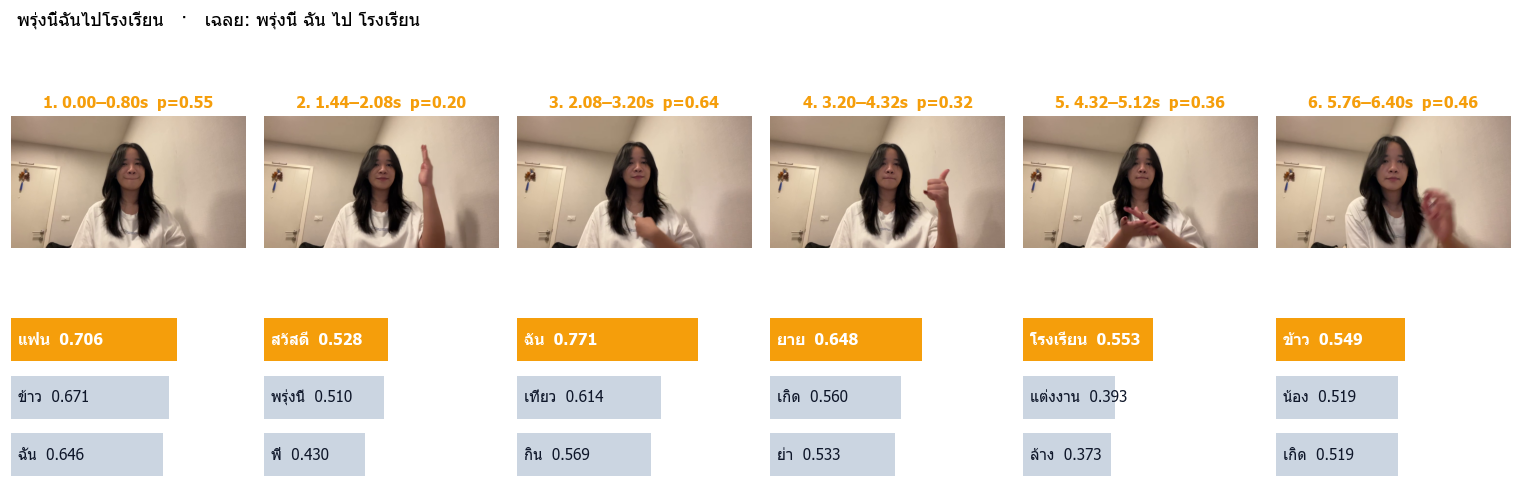

**วันหยุดพ่อชอบไปตลาด**

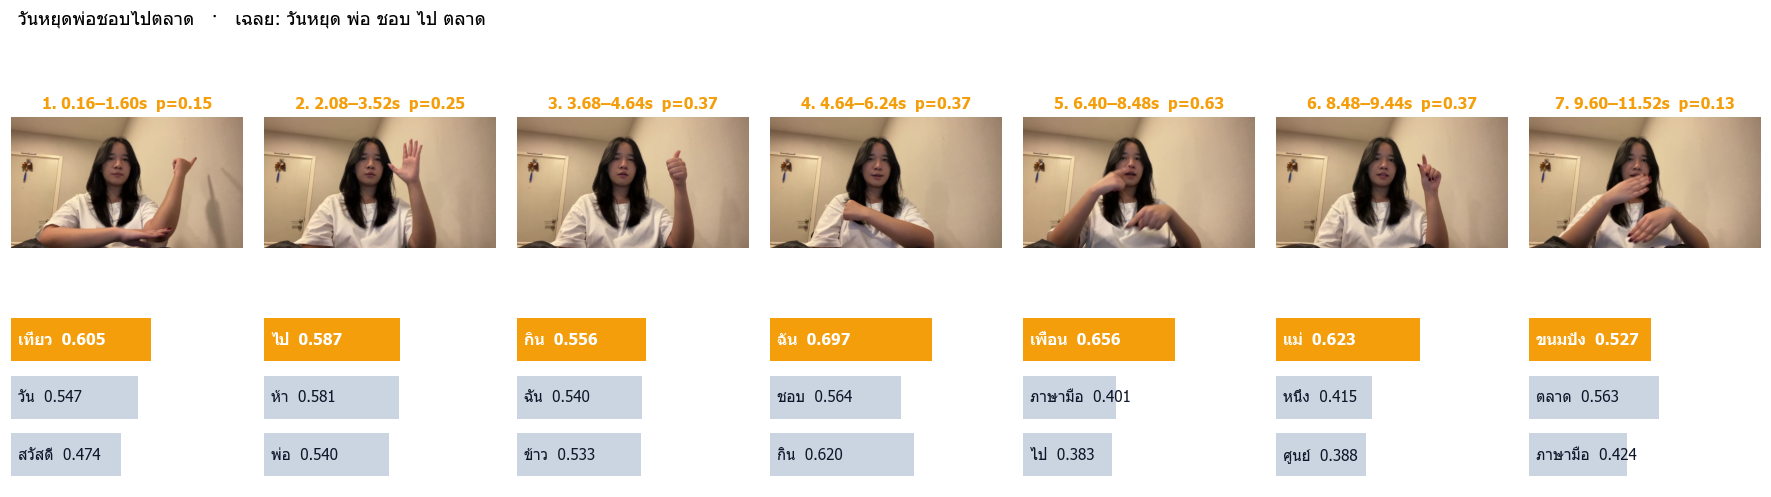

**สวัสดีฉันชื่อ P**

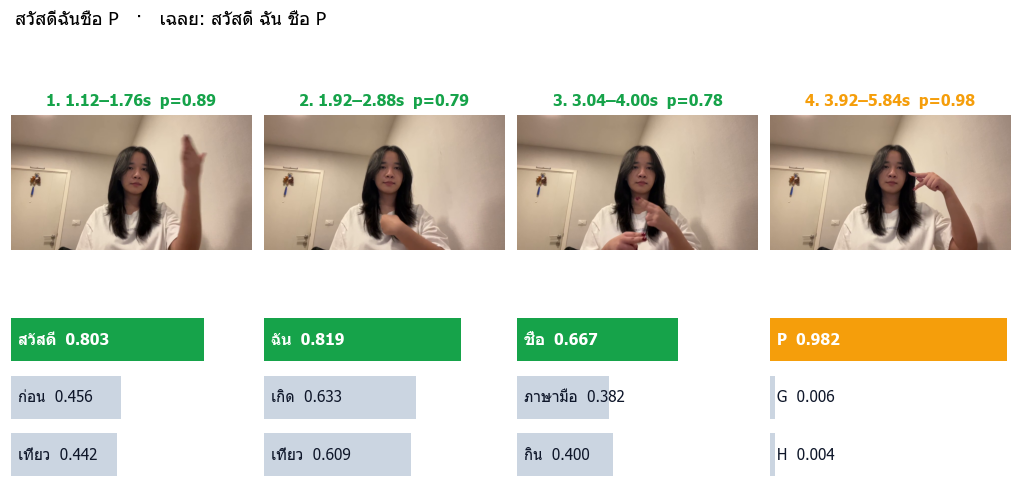

In [3]:
for s, name in [('data_test', 'data_test'), ('mine2', 'คลิปที่อัดเอง ตัดหัวท้าย + 2 คลิปใหม่')]:
    display(Markdown(f'### {name}'))
    for f in sorted((E / s).glob('*_timeline.png')):
        display(Markdown(f'**{f.stem.replace("_timeline", "")}**')); display(Image(filename=str(f)))